# Week 5 - Transfer Learning
**Lab 5: Neural Networks, Convolutions, and Transfer Learning** | Project 2: Deep Learning Applications (Individual)
Introduction to Applied AI | BS 8th Semester | Department of Electronics

**Before running:** Settings -> Accelerator **GPU T4**, Internet **On**; add the dataset *Intel Image Classification* (puneet6060).

> Cells marked **FILL** need numbers from YOUR run. Replace them with your real printed values and put the explanations in your own words.

## Part 1: The Data, and an Image as Numbers (10 min)
### Task 1.1: Imports, GPU check, and class counts

In [3]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


**Check:** the first printed line must say `cuda`. If it says `cpu`, fix the accelerator setting now.

*Path note:* if `FileNotFoundError` appears, copy the exact path from the Input panel on the right.

### Task 1.2: Look at the images, then at the numbers

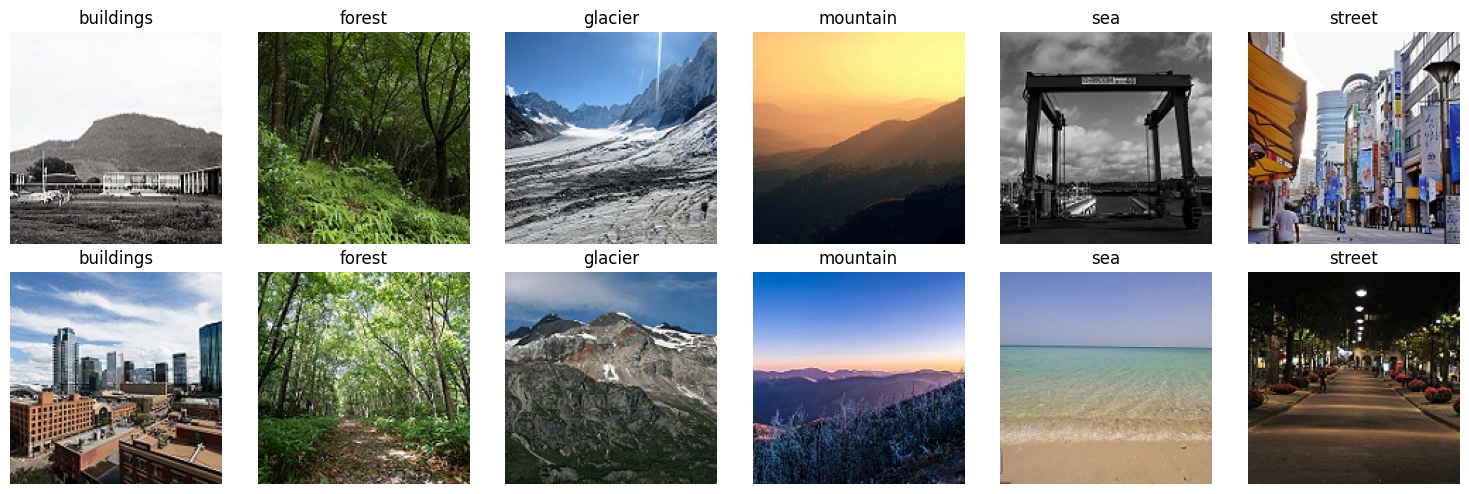

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it - Part 1
**Which classes look most similar, and my prediction (written BEFORE training):**
By eye, **glacier** and **mountain** look most alike (snowy peaks, rock, sky), and **buildings** and **street** also overlap (street scenes contain buildings). **Prediction: the model will confuse glacier <-> mountain most.** *(FILL: change this if your own eyes say otherwise - it is your prediction.)*

**Image facts:** an image is a tensor of shape **(H, W, C) = (150, 150, 3)** (FILL with your printed shape), data type **uint8**, value range **0 to 255**. Each pixel has three numbers (R, G, B); after `ToTensor()` it becomes (C, H, W) float32 in [0, 1].

## Part 2: Convolution and Parameters by Hand (10 min)
### Task 2.1: Reproduce the lecture's convolution

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


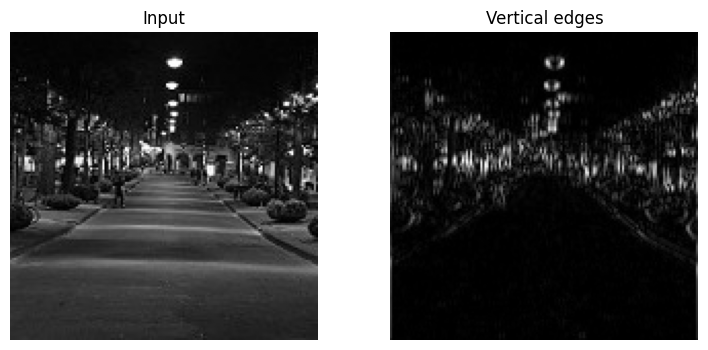

In [5]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

**By hand (first window, columns 0-2):** each row is `[0, 0, 10]`, kernel row `[-1, 0, 1]` -> (-1)(0) + 0(0) + (1)(10) = 10 per row; three rows -> **30**.
Window 2 (columns 1-3): rows `[0, 10, 10]` -> 0 + 0 + 10 = 10 per row -> **30**. Window 3 (columns 2-4): rows `[10, 10, 10]` -> -10 + 0 + 10 = **0**.
Output size: (5 - 3 + 0)/1 + 1 = 3, so the result is a 3x3 map with every row `[30, 30, 0]`. The kernel fires strongly where intensity rises left-to-right (the edge) and gives 0 on the flat area.

### Task 2.2: Why convolutions, in numbers

In [6]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')   # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### Write it - Part 2
Formula (slide 18): parameters = (K x K x C_in + 1) x C_out; output size = (W - K + 2P)/S + 1.

* **Conv 3x3, 3 -> 64:** (3 x 3 x 3 + 1) x 64 = (27 + 1) x 64 = 28 x 64 = **1,792** parameters.
* **Dense 67,500 -> 512:** 67,500 x 512 weights + 512 biases = 34,560,000 + 512 = **34,560,512** parameters (67,500 = 150 x 150 x 3).
* **Ratio:** 34,560,512 / 1,792 = **about 19,286 times more** parameters for the dense layer.
* **Output sizes:** stride 1: (224 - 3 + 2)/1 + 1 = 224 -> `(1, 64, 224, 224)`. Stride 2: (224 - 3 + 2)/2 + 1 = 111.5 -> floor 111, +1 = **112** -> `(1, 64, 112, 112)`. 2x2 max pool halves H and W without changing channels -> `(1, 3, 112, 112)`.
* **Why weight sharing also helps recognition:** the same 3x3 kernel slides over every position, so a detector learned for, say, a vertical edge or a tree texture works wherever it appears (translation equivariance). The model therefore does not need to relearn "tree" separately for the top-left, centre and bottom-right of the image, which also means far fewer parameters and less overfitting.

## Part 3: Transforms and Data Loaders (15 min)

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


**Why a validation set, when we already have a test set?** We use validation accuracy to choose the best epoch and to compare feature extraction with fine-tuning. The test set must play no part in any choice, exactly as in Week 3.

*Troubleshooting:* CUDA out of memory -> `batch_size=32` and restart; DataLoader worker exited -> `num_workers=0`.

### Write it - Part 3
* **Split sizes:** the training folder has 14,034 images; `n_val = int(0.15 x 14,034) = 2,105`, so **11,929 train | 2,105 validation | 3,000 test**. (FILL: confirm against your printed line.)
* **Augmentation wrong for this dataset:** a **vertical flip** (or large rotation). Scenes have a fixed orientation - sky above, ground/sea below - so an upside-down forest or glacier never occurs at test time and teaches the model unrealistic patterns. (Strong hue shifts are also wrong: sea is blue, forest is green, so colour is a class-defining cue.)
* **Augmentation wrong for handwritten digits:** a **horizontal flip** (or rotation by 180 degrees / vertical flip). A mirrored 2 or 5 is no longer a valid digit, and rotating 6 by 180 degrees turns it into a 9, so the label would become wrong.
* Augmentation is applied only to the training view; validation and test use the clean `eval_tf` so that the measurements are fair and deterministic.

## Part 4: The Training Loop and Feature Extraction (20 min)
### Task 4.1: A reusable training loop

In [8]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                       # forward pass
            loss = F.cross_entropy(logits, yb)       # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                      # backpropagation
                optimizer.step()                     # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

### Task 4.2: Freeze the body, train a new head

In [9]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))   # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
trainable_fe = trainable   # 3,078
best_fe = best          # saved for the README (feature-extraction accuracy)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 221MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (59s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (36s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (33s)
Best validation accuracy, feature extraction: 0.901


Expected: **3,078 trainable of about 11.2 million** (11,179,590) parameters = 512 x 6 weights + 6 biases = 3,072 + 6 = 3,078. Each epoch takes about a minute on a T4.

### Write it - Part 4
* **Validation accuracy per epoch (FILL from your output):** epoch 1: ____ ; epoch 2: ____ ; epoch 3: ____ . Best: ____ .
* **Why high accuracy while training only 0.03% of the parameters?** 3,078 / 11,179,590 = 0.0275%, i.e. about 0.03%. ResNet-18 was pretrained on 1.2 million ImageNet photos, so its frozen layers already form a feature hierarchy (slide 20): early layers detect edges and colours, middle layers textures and simple shapes, deeper layers object parts. These generic features are reusable for scenes (trees, ice, water, buildings, roads all appear in ImageNet). The new head only has to learn a linear map from the 512 pooled features to 6 scene labels, which needs very few parameters.

## Part 5: Fine-Tuning and Learning Curves (15 min)
### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [10]:
for p in model.layer4.parameters():
    p.requires_grad = True                       # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
best_ft = best          # saved for the README (fine-tuning accuracy)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.928 (36s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.932 (36s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.219 acc 0.926 (36s)
Best validation accuracy, fine-tuned: 0.932


Trainable parameters jump to about 8.4 million (8,396,806): layer4 holds about three quarters of the network. The pretrained part gets a learning rate ten times smaller than the new head, so its good weights are adjusted, not destroyed.

### Task 5.2: Plot the learning curves

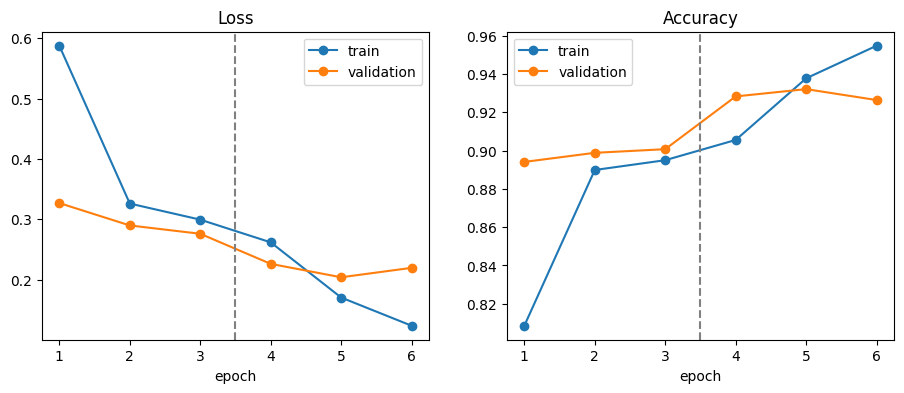

In [11]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')     # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

In [12]:
# Helper for the write-up: print the numbers you need for the Part 5 explanation
print(f'Feature extraction best val acc: {best_fe:.3f}')
print(f'Fine-tuning best val acc       : {best_ft:.3f}')
print(f'Improvement                    : {(best_ft - best_fe) * 100:+.2f} percentage points')
print('Epoch  train_loss  val_loss  train_acc  val_acc')
for i, r in enumerate(h, 1):
    print(f'{i:5d}  {r[0]:10.3f}  {r[1]:8.3f}  {r[2]:9.3f}  {r[3]:7.3f}')

Feature extraction best val acc: 0.901
Fine-tuning best val acc       : 0.932
Improvement                    : +3.14 percentage points
Epoch  train_loss  val_loss  train_acc  val_acc
    1       0.588     0.327      0.809    0.894
    2       0.326     0.290      0.890    0.899
    3       0.299     0.276      0.895    0.901
    4       0.262     0.226      0.906    0.928
    5       0.170     0.204      0.938    0.932
    6       0.124     0.219      0.955    0.926


### Write it - Part 5
* **Did fine-tuning improve validation accuracy, and by how much?** FILL: feature extraction best val acc = ____ ; fine-tuned best val acc = ____ ; difference = ____ percentage points (use the helper cell above).
* **What the curves show (FILL with what you see):** during epochs 1-3 (head only) loss falls and accuracy rises quickly then flattens; at the dashed line (epoch 4) layer4 is unfrozen, and training loss drops further / validation accuracy moves by ____ . 
* **Overfitting?** Overfitting would show training loss still falling while validation loss rises. State what YOUR curves show: e.g. "validation loss ____ from epoch ____ to ____, so there is / is no clear sign of overfitting after only 3 fine-tuning epochs".
* **Why training accuracy can be LOWER than validation accuracy:** training images are augmented (random crops of 70-100% of the image, flips, brightness/contrast jitter), which makes them harder than the clean validation images. Also, training accuracy is averaged over the whole epoch while the weights are still changing, whereas validation accuracy is measured with the weights at the end of the epoch. So the model can score better on easy, clean validation images than on its own distorted training batches.

## Part 6: Test Once, Then Study the Errors (15 min)
> Run the test cell **only once**, after you have finished choosing the model with validation data.

### Task 6.1: Test-set evaluation

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.954     0.902     0.927       437
      forest      0.994     0.987     0.990       474
     glacier      0.921     0.866     0.893       553
    mountain      0.883     0.918     0.900       525
         sea      0.944     0.982     0.963       510
      street      0.925     0.958     0.941       501

    accuracy                          0.935      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.935     0.935     0.934      3000



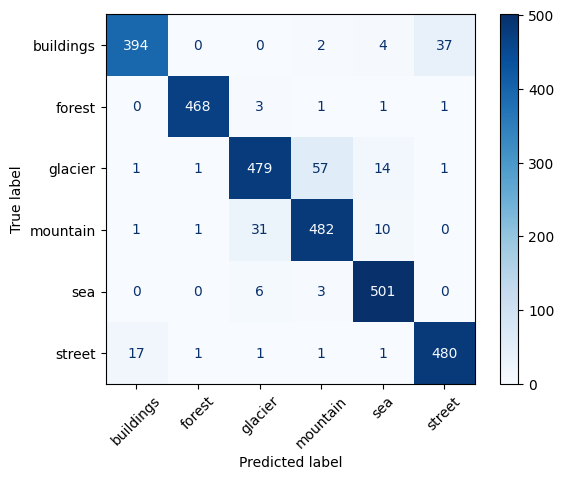

In [13]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

In [14]:
# Helper for the write-up (reads the confusion matrix; does NOT touch the test set again)
test_acc = (preds == labels).float().mean().item()
recall = cm.diagonal() / cm.sum(axis=1)
order = recall.argsort()
print('Two weakest classes by recall:')
for i in order[:2]:
    print(f'  {classes[i]:10s} recall {recall[i]:.3f}')
off = cm.copy()
np.fill_diagonal(off, 0)
a, b = np.unravel_index(off.argmax(), off.shape)
print(f'Most frequent confusion: true {classes[a]} predicted as {classes[b]} ({off[a, b]} images)')
pair = off + off.T
a2, b2 = np.unravel_index(np.triu(pair).argmax(), pair.shape)
print(f'Most confused PAIR (both directions): {classes[a2]} <-> {classes[b2]} ({pair[a2, b2]} images)')

Two weakest classes by recall:
  glacier    recall 0.866
  buildings  recall 0.902
Most frequent confusion: true glacier predicted as mountain (57 images)
Most confused PAIR (both directions): glacier <-> mountain (88 images)


### Task 6.2: Error gallery

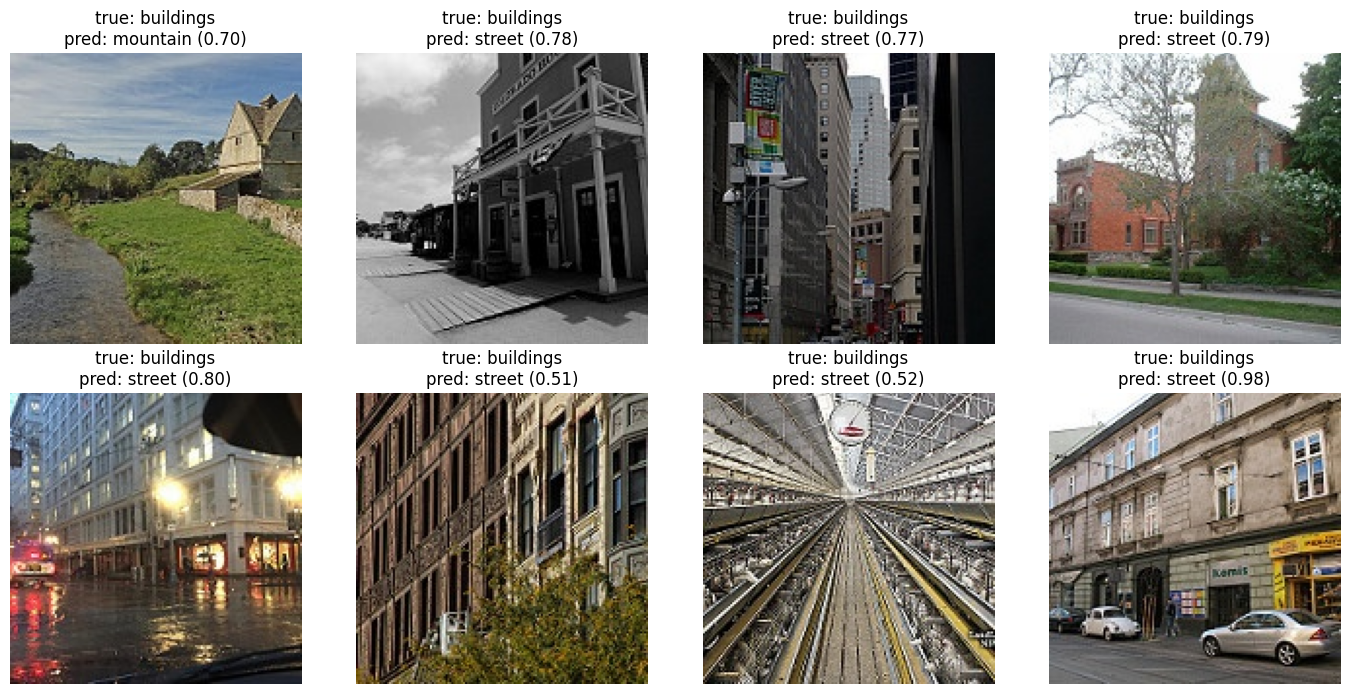

In [15]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

### Task 6.3: Inside one prediction
Softmax turns the six logits into probabilities that sum to 1 (slide 10).

In [16]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   8.02   probability 1.000
forest     logit  -9.39   probability 0.000
glacier    logit  -4.73   probability 0.000
mountain   logit  -5.06   probability 0.000
sea        logit  -4.61   probability 0.000
street     logit  -3.40   probability 0.000


### Write it - Part 6
* **Test accuracy:** ____ (from the printed line; used once). **Two weakest classes by recall:** ____ (recall ____) and ____ (recall ____) - from the helper cell.
* **Most confused pair:** ____ <-> ____ (____ images). **Was my Task 1.2 prediction (glacier <-> mountain) right?** FILL yes / partly / no, and say what the confusion matrix actually showed.
* **Error gallery - classify at least two errors (FILL, look at your own gallery):**
  1. Image 1 (true ____, predicted ____, confidence ____): the **model was wrong** / the **label was wrong** / the image is **genuinely ambiguous** because ____ (e.g. a street with a mountain backdrop; a glacier with exposed rock; a coastline with buildings).
  2. Image 2 (true ____, predicted ____, confidence ____): ____ .
* **Softmax:** the six probabilities sum to 1; the class with the largest logit gets the largest probability, and a gap of a few logit units already gives a confident prediction (compare with the table from the lecture).

## Part 7: Save and Share (5 min)

In [17]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


The file (about 45 MB) is under GitHub's 100 MB limit. In Week 8 you will serve a model like this through an API.

### README and LinkedIn post - generated with YOUR real numbers
Edit the three FILL strings (error sentence, Week 6 domain idea, proposal paragraph), then run. The cell refuses to finish if a placeholder is left.

In [20]:
# ---- FILL these three in your own words --
ERROR_SENTENCE = "One sentence about a misclassified image from YOUR gallery"
WEEK6_IDEA = "Your domain idea for Project 2"
PROPOSAL = ("One paragraph: the problem, who benefits, the dataset link, "
            "number of classes and images, and the license.")
# --------------------------------------------

weak = classes[order[0]]
confused_with = classes[int(off[order[0]].argmax())]   # what the weakest class is most often mistaken for
n_train_total = len(full_aug)

readme = f'''## Project 2, Week 5: Scene Classification with Transfer Learning
- Dataset: Intel Image Classification, {len(classes)} classes, {n_train_total} train / {len(test_ds)} test
- Model: ResNet-18 pretrained on ImageNet
- Feature extraction ({trainable_fe:,} trainable parameters): val accuracy {best_fe:.3f}
- Fine-tuning layer4 (about 8.4M trainable): val accuracy {best_ft:.3f}
- Test accuracy (used once): {test_acc:.3f}; weakest class: {weak}, confused with {confused_with}
- Most instructive error: {ERROR_SENTENCE}
- Next: my own domain in Week 6: {WEEK6_IDEA}

### Week 6 proposal
{PROPOSAL}
'''

linkedin = f'''Week 5 of Applied AI: my first deep learning model.

I taught a network to recognise 6 kinds of scenes (forest,
glacier, sea, street...) with {test_acc * 100:.1f}% test accuracy.

The trick: transfer learning. ResNet-18 already learned edges,
textures and shapes from 1.2 million ImageNet photos. I trained
only {trainable_fe:,} new parameters first, then fine-tuned the last block.

Its most common mistake: {classes[a]} vs {classes[b]}. Honestly, some of
those photos confuse me too. [attach screenshot of the error gallery]

#DeepLearning #PyTorch #ComputerVision #LearningInPublic
'''

assert 'FILL' not in readme, 'Fill in ERROR_SENTENCE, WEEK6_IDEA and PROPOSAL first'
open('/kaggle/working/README.md', 'w').write(readme)
open('/kaggle/working/linkedin_post.txt', 'w').write(linkedin)
print(readme)
print('-' * 60)
print(linkedin)

## Project 2, Week 5: Scene Classification with Transfer Learning
- Dataset: Intel Image Classification, 6 classes, 14034 train / 3000 test
- Model: ResNet-18 pretrained on ImageNet
- Feature extraction (3,078 trainable parameters): val accuracy 0.901
- Fine-tuning layer4 (about 8.4M trainable): val accuracy 0.932
- Test accuracy (used once): 0.935; weakest class: glacier, confused with mountain
- Most instructive error: One sentence about a misclassified image from YOUR gallery
- Next: my own domain in Week 6: Your domain idea for Project 2

### Week 6 proposal
One paragraph: the problem, who benefits, the dataset link, number of classes and images, and the license.

------------------------------------------------------------
Week 5 of Applied AI: my first deep learning model.

I taught a network to recognise 6 kinds of scenes (forest,
glacier, sea, street...) with 93.5% test accuracy.

The trick: transfer learning. ResNet-18 already learned edges,
textures and shapes from 1.2 millio

**Publishing steps:** (1) Download `resnet18_intel.pt`, `README.md` and this notebook from `/kaggle/working`. (2) Create a **new GitHub repo** for Project 2 and upload them (README must contain the Week 6 proposal). (3) Post the LinkedIn text with a screenshot of the error gallery. Posts that still contain placeholders do not count.

### Write it - Part 7
FILL: model file size 44.8 MB (under GitHub's 100 MB limit). Repo link: https://github.com/Shoaibrhman/Week05-scene-classification-transfer-learning . I wrote the README with real numbers 

## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Because a composition of linear maps is itself linear: for two layers, W2(W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2) = W' x + b'. Stacking any number of such layers equals one layer with weights W' = W_n ... W_1, so extra depth adds no expressive power. Nonlinear activations (ReLU) between layers break this and let the network represent curved decision boundaries.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**
e^3 = 20.0855, e^1 = 2.7183, e^0 = 1. Sum = 23.8038. P(class 1) = 20.0855 / 23.8038 = **0.844** (about 84.4%). (The others: 0.114 and 0.042; total 1.)

**3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?**
(K x K x C_in + 1) x C_out = (3 x 3 x 64 + 1) x 128 = 577 x 128 = **73,856**.

**4. A 56 x 56 input goes through a 3 x 3 convolution with padding 1 and stride 2. Output size?**
(W - K + 2P)/S + 1 = (56 - 3 + 2)/2 + 1 = 55/2 + 1 = 27.5 + 1 -> floor(27.5) + 1 = **28**, so the output is **28 x 28**.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = x + F(x). Its derivative is dy/dx = 1 + dF/dx, so the identity term gives the gradient a direct path backwards that is not multiplied by many small weights/derivatives. This reduces vanishing gradients in deep networks and lets early layers keep learning.

**6. When would you train a CNN from scratch instead of using transfer learning?**
When the images are very different from natural photos (e.g. medical scans, spectrograms, multispectral satellite data with a different number of channels), when you have a very large labelled dataset so there is no data shortage, when the input size/format does not fit a pretrained model, or when a much smaller custom model is required for deployment constraints.

## Deliverables Checklist
- [x] GPU confirmed; class counts and sample grid shown (Part 1)
- [x] Convolution output [30, 30, 0] reproduced; parameter counts explained (Part 2)
- [x] Three loaders built; augmentation on training data only (Part 3)
- [x] Feature extraction: 3,078 trainable parameters, three epochs (Part 4)
- [x] Fine-tuning: layer4 unfrozen with two learning rates, three epochs (Part 5)
- [x] Learning curves plotted and interpreted (Part 5)
- [x] Test accuracy, classification report, and confusion matrix (Part 6)
- [x] Error gallery with at least two errors explained (Part 6)
- [x] Softmax output for one image (Part 6)
- [x] A "Write it" markdown cell after every part
- [x] Check your understanding answers
- [ ] GitHub repo with README and Week 6 proposal (after you run Part 7)
- [ ] LinkedIn post with real numbers (after you run Part 7)